
# MuRIL + XLM-RoBERTa Hybrid — 5-Fold User-Grouped Cross-Validation

**Research experiment:** Compare frozen multilingual representations from MuRIL and XLM-RoBERTa, then test whether feature-level fusion improves code-mixed offensive-language detection.

## Models compared

| Track | Text representation | Classifier |
|---|---|---|
| A | MuRIL (`google/muril-base-cased`) | MLP |
| B | XLM-RoBERTa (`FacebookAI/xlm-roberta-base`) | MLP |
| C | Concatenated MuRIL + XLM-R embeddings | Hybrid MLP |
| D | Average of A + B out-of-fold probabilities | Late-fusion ensemble |

**Hybrid architecture:** mean-pooled token representations from both pretrained encoders are concatenated (`768 + 768 = 1536` dimensions) and passed to a trainable MLP classifier.

## Evaluation protocol

- Use only the official `train.csv` rows for 5-fold cross-validation.
- Group known users together. For rows with missing user metadata, fall back to source ID; if ID is also missing, fall back to normalized text.
- Do not use `user`, `id`, `state`, or `time` as model features.
- Fit the MLP and feature scaler independently inside each fold.
- Select each fold's classifier checkpoint using validation Macro-F1.
- Keep official `dev.csv` and `test.csv` outside cross-validation. They are loaded only for a data/overlap audit, not for fitting or selecting models.

## Important interpretation

The pretrained encoders are **frozen** in this experiment. This makes the 5-fold comparison feasible on a Kaggle T4 and isolates the value of their representations and fusion. This is a *frozen-embedding hybrid*, not joint end-to-end fine-tuning of both transformer backbones. The next experiment can fine-tune the best architecture.

The current MuRIL + Focal Loss result from the previous single official-dev run (Accuracy 82.32%, Macro-F1 80.40%) is a useful historical reference, but it is **not directly comparable** to the new grouped-CV results because the evaluation protocol differs.


## Run status / correction note

The uploaded v5 execution reached embedding extraction successfully, then stopped at the first fold because `precision_recall_fscore_support` was missing from imports. This repaired copy imports that metric explicitly, includes a pre-training metric self-test, and clears stale partial outputs. No cross-validation scores are claimed until this repaired notebook completes all folds.

The observed split audit had 60,000 train rows, 20,000 dev rows, and 20,000 test rows. In the uploaded run, train had 11 non-null user values, 9,760 shared non-null IDs with dev, and 717 shared normalized texts with dev. User-group CV produced five folds with zero overlap by its assigned grouping key, but 762 normalized text values appeared across different groups; disclose this residual duplicate-text risk in reporting.


In [1]:

# ============================================================
# 1. ENVIRONMENT + REPRODUCIBILITY
# ============================================================
import os, sys, gc, re, json, math, time, random, hashlib, subprocess, importlib.util, unicodedata
from pathlib import Path

if importlib.util.find_spec("transformers") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "transformers>=4.45,<5"])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import DataLoader, TensorDataset
from transformers import AutoTokenizer, AutoModel
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    precision_recall_fscore_support,
    classification_report, confusion_matrix, roc_auc_score,
    average_precision_score, roc_curve, precision_recall_curve
)
from IPython.display import display

RANDOM_STATE = 42
def set_seed(seed=RANDOM_STATE):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: no GPU detected; embedding extraction will be slow.")

print("PyTorch:", torch.__version__)
print("Device:", device)


GPU: Tesla T4
PyTorch: 2.11.0+cu128
Device: cuda


In [2]:

# ============================================================
# 2. CONFIGURATION
# ============================================================
DATASET_DIR = Path("/kaggle/input/datasets/mdnishatraihan/code-mixed-offensive-bangla-english-hindi")
SEARCH_ROOTS = [Path("/kaggle/input"), Path("."), Path("/mnt/data"), Path("/content")]

MURIL_CHECKPOINT = "google/muril-base-cased"
XLMR_CHECKPOINT = "FacebookAI/xlm-roberta-base"

N_SPLITS = 5
MAX_LENGTH = 128
EMBED_BATCH_SIZE = 16          # reduce to 8 if a GPU out-of-memory error occurs
MLP_BATCH_SIZE = 256
MLP_EPOCHS = 25
MLP_PATIENCE = 5
MLP_LEARNING_RATE = 1e-3
MLP_WEIGHT_DECAY = 1e-4
FOCAL_GAMMA = 2.0
DROPOUT = 0.30

# Set a small integer (e.g. 3000) only for a quick smoke test.
# Keep None for the full 60K-row experiment and research reporting.
MAX_TRAIN_ROWS_FOR_DEBUG = None

WORK_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()
CACHE_DIR = WORK_DIR / "hybrid_cv_embedding_cache"
MODEL_DIR = WORK_DIR / "hybrid_cv_fold_models"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

USE_AMP = device.type == "cuda"
print("Work directory:", WORK_DIR)
print("Embedding batch size:", EMBED_BATCH_SIZE)
print("CV:", N_SPLITS, "folds")


Work directory: /kaggle/working
Embedding batch size: 16
CV: 5 folds


In [3]:

# ============================================================
# 3. FIND AND LOAD OFFICIAL SPLITS
# ============================================================
def find_dataset_file(filename):
    preferred = DATASET_DIR / filename
    if preferred.exists():
        return preferred

    candidates = []
    for root in SEARCH_ROOTS:
        if root.exists():
            candidates.extend(root.rglob(filename))
    candidates = list(dict.fromkeys(candidates))

    # Prefer a result from the named Kaggle dataset directory.
    named = [p for p in candidates if "code-mixed-offensive-bangla-english-hindi" in str(p).lower()]
    if named:
        return sorted(named, key=lambda p: len(str(p)))[0]
    if candidates:
        return sorted(candidates, key=lambda p: len(str(p)))[0]
    return None

TRAIN_PATH = find_dataset_file("train.csv")
DEV_PATH = find_dataset_file("dev.csv")
TEST_PATH = find_dataset_file("test.csv")

if TRAIN_PATH is None:
    raise FileNotFoundError(
        "train.csv not found. Add the Kaggle dataset: "
        "mdnishatraihan/code-mixed-offensive-bangla-english-hindi"
    )

train = pd.read_csv(TRAIN_PATH)
dev = pd.read_csv(DEV_PATH) if DEV_PATH else None
test = pd.read_csv(TEST_PATH) if TEST_PATH else None

required = {"text", "label"}
if not required.issubset(train.columns):
    raise ValueError(f"train.csv must include columns {required}; got {train.columns.tolist()}")

train = train.dropna(subset=["label"]).copy().reset_index(drop=True)
train["text"] = train["text"].fillna("").astype(str)
train["label"] = train["label"].astype(str).str.strip()

if MAX_TRAIN_ROWS_FOR_DEBUG is not None:
    train = train.sample(
        n=min(MAX_TRAIN_ROWS_FOR_DEBUG, len(train)),
        random_state=RANDOM_STATE
    ).reset_index(drop=True)

print("TRAIN:", TRAIN_PATH, train.shape)
print("DEV  :", DEV_PATH, None if dev is None else dev.shape)
print("TEST :", TEST_PATH, None if test is None else test.shape)

display(train.head(5))
display(
    train["label"].value_counts()
    .rename_axis("label")
    .to_frame("count")
    .assign(percent=lambda x: (100*x["count"]/len(train)).round(2))
)


TRAIN: /kaggle/input/datasets/mdnishatraihan/code-mixed-offensive-bangla-english-hindi/train.csv (60000, 6)
DEV  : /kaggle/input/datasets/mdnishatraihan/code-mixed-offensive-bangla-english-hindi/dev.csv (20000, 6)
TEST : /kaggle/input/datasets/mdnishatraihan/code-mixed-offensive-bangla-english-hindi/test.csv (20000, 6)


,id,text,user,state,time,label
0,39056.0,@USER I’m একজন অসুস্থ भाड़ में जाओ मैं পছন্দ ক...,steve11,CT,9:25:20,OFF
1,72660.0,@USER @USER আপনি মিস করেছেন seeing Pruitt chew...,jennifer55,CT,7:14:19,OFF
2,86747.0,.@USER says she’s में एक रिपब्लिकन এর ছাঁচ लिं...,ann87,FL,4:03:26,NOT
3,NaN,@USER @USER @USER সম্ভবত সে बेरहमी से पिटाई के...,NaN,NaN,NaN,OFF
4,78407.0,@USER @USER @USER @USER @USER @USER @USER @USE...,george45,DE,4:52:15,NOT


,count,percent
label,,
NOT,40018,66.7
OFF,19982,33.3


In [4]:

# ============================================================
# 4. DATA QUALITY + CROSS-SPLIT OVERLAP AUDIT
# ============================================================
def normalize_for_grouping(value):
    value = "" if pd.isna(value) else str(value)
    value = unicodedata.normalize("NFKC", value).lower()
    value = re.sub(r"[\u200B-\u200D\uFEFF]", " ", value)
    value = re.sub(r"\s+", " ", value).strip()
    return value

train["_norm_text"] = train["text"].map(normalize_for_grouping)

split_rows = []
for name, frame in [("train", train), ("dev", dev), ("test", test)]:
    if frame is None:
        continue
    split_rows.append({
        "split": name,
        "rows": len(frame),
        "missing_text": int(frame["text"].isna().sum()) if "text" in frame else None,
        "missing_label": int(frame["label"].isna().sum()) if "label" in frame else None,
        "unique_text": int(frame["text"].fillna("").astype(str).nunique()) if "text" in frame else None,
        "unique_id": int(frame["id"].nunique(dropna=True)) if "id" in frame else None,
        "unique_user": int(frame["user"].nunique(dropna=True)) if "user" in frame else None,
    })

display(pd.DataFrame(split_rows))

def value_overlap(a, b, col):
    if a is None or b is None or col not in a.columns or col not in b.columns:
        return None
    av = set(a[col].dropna().astype(str))
    bv = set(b[col].dropna().astype(str))
    return len(av & bv)

if dev is not None:
    dev_copy = dev.copy()
    dev_copy["text"] = dev_copy["text"].fillna("").astype(str)
    dev_copy["_norm_text"] = dev_copy["text"].map(normalize_for_grouping)
    overlap_table = pd.DataFrame([
        {"check": "Shared non-null source IDs", "count": value_overlap(train, dev_copy, "id")},
        {"check": "Shared normalized text values", "count": value_overlap(train.assign(_norm_text=train["_norm_text"]), dev_copy, "_norm_text")},
    ])
    display(overlap_table)
    print("Note: dev/test are not used in the cross-validation training below.")

if test is not None and "label" in test.columns:
    print("Test labels are present in the source file, but are not read by any CV training function.")


,split,rows,missing_text,missing_label,unique_text,unique_id,unique_user
0,train,60000,0,0,58765,13187,11
1,dev,20000,0,0,19853,9812,11
2,test,20000,0,0,19873,9829,11


,check,count
0,Shared non-null source IDs,9760
1,Shared normalized text values,717


Note: dev/test are not used in the cross-validation training below.
Test labels are present in the source file, but are not read by any CV training function.



## 5. Leakage-aware fold construction

For this dataset, only 11 non-missing user identities were observed in the inspected training file, and some users are strongly associated with one label. Therefore, user-grouped folds are essential to reveal whether the classifier generalizes beyond known users, but fold-level support must be reported because groups are not equally sized.

Grouping rule:
1. Known user → all rows from that user stay in one fold.
2. Missing user but known source ID → group by source ID.
3. Missing user and source ID → group by normalized text.

This grouping key is used **only for fold assignment**, never as a model feature. The notebook also reports exact-text duplicates that cross different groups; those residual cases are disclosed rather than silently hidden.


In [5]:

# ============================================================
# 6. BUILD USER-GROUPED CV KEYS + STRATIFIED 5-FOLD SPLITS
# ============================================================
def build_user_groups(frame):
    keys = []
    for pos, row in enumerate(frame.itertuples(index=False)):
        row_map = row._asdict()
        user_val = row_map.get("user", None)
        id_val = row_map.get("id", None)
        text_val = row_map.get("_norm_text", row_map.get("text", ""))

        user_missing = pd.isna(user_val) or not str(user_val).strip()
        id_missing = pd.isna(id_val) or not str(id_val).strip()

        if not user_missing:
            key = "USER::" + str(user_val).strip().casefold()
        elif not id_missing:
            key = "ID::" + str(id_val).strip().casefold()
        else:
            text_key = normalize_for_grouping(text_val)
            key = "TEXT::" + text_key if text_key else f"ROW::{pos}"
        keys.append(key)
    return np.asarray(keys, dtype=object)

cv_groups = build_user_groups(train)
label_names = ["NOT", "OFF"]
unexpected_labels = sorted(set(train["label"]) - set(label_names))
if unexpected_labels:
    raise ValueError(f"Unexpected labels {unexpected_labels}; expected NOT and OFF.")

label2id = {"NOT": 0, "OFF": 1}
id2label = {v: k for k, v in label2id.items()}
y = train["label"].map(label2id).to_numpy(dtype=np.int64)

print("Rows:", len(train))
print("Distinct CV groups:", len(np.unique(cv_groups)))
print("Known user identities:", train["user"].nunique(dropna=True) if "user" in train else 0)

# Residual normalized-text duplicates spanning more than one group.
text_group_audit = pd.DataFrame({
    "norm_text": train["_norm_text"],
    "group": cv_groups
})
cross_group_text = (
    text_group_audit[text_group_audit["norm_text"].ne("")]
    .groupby("norm_text")["group"].nunique()
)
cross_group_duplicate_texts = int((cross_group_text > 1).sum())
print("Normalized texts appearing in multiple user/source groups:", cross_group_duplicate_texts)

cv = StratifiedGroupKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)
folds = list(cv.split(np.zeros(len(y)), y, groups=cv_groups))

fold_rows = []
for fold_no, (fit_idx, val_idx) in enumerate(folds, start=1):
    group_overlap = len(set(cv_groups[fit_idx]) & set(cv_groups[val_idx]))
    val_counts = pd.Series(y[val_idx]).value_counts().reindex([0, 1], fill_value=0)
    fold_rows.append({
        "fold": fold_no,
        "train_rows": len(fit_idx),
        "validation_rows": len(val_idx),
        "validation_NOT": int(val_counts.loc[0]),
        "validation_OFF": int(val_counts.loc[1]),
        "validation_OFF_ratio": float(val_counts.loc[1] / len(val_idx)),
        "group_overlap": group_overlap,
    })

fold_distribution = pd.DataFrame(fold_rows)
display(fold_distribution)
assert (fold_distribution["group_overlap"] == 0).all(), "User/source group leakage exists between a fold's train and validation portions."
assert all(len(np.unique(y[val_idx])) == 2 for _, val_idx in folds), "At least one validation fold lacks a class."


Rows: 60000
Distinct CV groups: 12326
Known user identities: 11
Normalized texts appearing in multiple user/source groups: 762


,fold,train_rows,validation_rows,validation_NOT,validation_OFF,validation_OFF_ratio,group_overlap
0,1,49523,10477,7347,3130,0.298750,0
1,2,46247,13753,8297,5456,0.396713,0
2,3,47970,12030,8415,3615,0.300499,0
3,4,48136,11864,8152,3712,0.312879,0
4,5,48124,11876,7807,4069,0.342624,0



## 7. Extract frozen multilingual embeddings

The two encoders are run separately to reduce peak GPU memory. Mean pooling uses the attention mask so padding tokens do not influence the sentence vector. The resulting embeddings are cached under `/kaggle/working` and reused if the same text list, checkpoint, and max length are present.

- MuRIL checkpoint: `google/muril-base-cased`
- XLM-R checkpoint: `FacebookAI/xlm-roberta-base`

XLM-R is a multilingual RoBERTa model with broad multilingual pretraining; both checkpoints are loaded through Hugging Face Transformers. <https://huggingface.co/FacebookAI/xlm-roberta-base> · <https://huggingface.co/google/muril-base-cased>


In [6]:

# ============================================================
# 8. FROZEN ENCODER EMBEDDING EXTRACTION + CACHE
# ============================================================
def text_fingerprint(texts, checkpoint, max_length):
    h = hashlib.sha256()
    h.update(checkpoint.encode("utf-8"))
    h.update(str(max_length).encode("utf-8"))
    for text in texts:
        h.update(str(text).encode("utf-8", errors="ignore"))
        h.update(b"\n")
    return h.hexdigest()[:20]

def extract_mean_embeddings(
    texts,
    checkpoint,
    cache_prefix,
    max_length=MAX_LENGTH,
    batch_size=EMBED_BATCH_SIZE
):
    texts = [str(t) for t in texts]
    fingerprint = text_fingerprint(texts, checkpoint, max_length)
    cache_path = CACHE_DIR / f"{cache_prefix}_{fingerprint}.npy"

    if cache_path.exists():
        cached = np.load(cache_path, mmap_mode="r")
        if cached.shape[0] == len(texts):
            print(f"Loaded cached embeddings: {cache_path.name} {cached.shape}")
            return np.asarray(cached, dtype=np.float32)

    print(f"\nExtracting embeddings with {checkpoint}")
    tokenizer = AutoTokenizer.from_pretrained(checkpoint, use_fast=True)
    encoder = AutoModel.from_pretrained(checkpoint)
    encoder.to(device)
    encoder.eval()

    all_vectors = []
    start_time = time.time()

    for start in range(0, len(texts), batch_size):
        batch_texts = texts[start:start + batch_size]
        encoded = tokenizer(
            batch_texts,
            truncation=True,
            max_length=max_length,
            padding=True,
            return_tensors="pt"
        )
        encoded = {k: v.to(device) for k, v in encoded.items()}

        with torch.no_grad():
            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=USE_AMP
            ):
                outputs = encoder(**encoded, return_dict=True)
                # Accumulate masked pooling in float32 for numerical stability.
                hidden = outputs.last_hidden_state.float()
                mask = encoded["attention_mask"].unsqueeze(-1).float()
                pooled = (hidden * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1.0)

        all_vectors.append(pooled.float().cpu().numpy())

        if (start // batch_size + 1) % 100 == 0 or start + batch_size >= len(texts):
            done = min(start + batch_size, len(texts))
            print(f"  {done:,}/{len(texts):,} texts encoded")

    embeddings = np.concatenate(all_vectors, axis=0).astype(np.float32)
    np.save(cache_path, embeddings.astype(np.float16))
    print(
        f"Created {embeddings.shape} embeddings in "
        f"{(time.time()-start_time)/60:.1f} minutes."
    )

    del encoder, tokenizer, all_vectors
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return embeddings

train_texts = train["text"].fillna("").astype(str).tolist()

muril_embeddings = extract_mean_embeddings(
    train_texts,
    checkpoint=MURIL_CHECKPOINT,
    cache_prefix="muril",
)
xlmr_embeddings = extract_mean_embeddings(
    train_texts,
    checkpoint=XLMR_CHECKPOINT,
    cache_prefix="xlmr",
)

assert muril_embeddings.shape[0] == len(train)
assert xlmr_embeddings.shape[0] == len(train)
assert muril_embeddings.shape[1] == xlmr_embeddings.shape[1], (
    "Fusion code expects equal embedding dimensions; project each to a common dimension if checkpoints differ."
)

print("MuRIL embeddings:", muril_embeddings.shape)
print("XLM-R embeddings:", xlmr_embeddings.shape)



Extracting embeddings with google/muril-base-cased


config.json:   0%|          | 0.00/411 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/206 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/3.16M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/113 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  953MB            

... (11 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  1,600/60,000 texts encoded
  3,200/60,000 texts encoded
  4,800/60,000 texts encoded
  6,400/60,000 texts encoded
  8,000/60,000 texts encoded
  9,600/60,000 texts encoded
  11,200/60,000 texts encoded
  12,800/60,000 texts encoded
  14,400/60,000 texts encoded
  16,000/60,000 texts encoded
  17,600/60,000 texts encoded
  19,200/60,000 texts encoded
  20,800/60,000 texts encoded
  22,400/60,000 texts encoded
  24,000/60,000 texts encoded
  25,600/60,000 texts encoded
  27,200/60,000 texts encoded
  28,800/60,000 texts encoded
  30,400/60,000 texts encoded
  32,000/60,000 texts encoded
  33,600/60,000 texts encoded
  35,200/60,000 texts encoded
  36,800/60,000 texts encoded
  38,400/60,000 texts encoded
  40,000/60,000 texts encoded
  41,600/60,000 texts encoded
  43,200/60,000 texts encoded
  44,800/60,000 texts encoded
  46,400/60,000 texts encoded
  48,000/60,000 texts encoded
  49,600/60,000 texts encoded
  51,200/60,000 texts encoded
  52,800/60,000 texts encoded
  54,400/60,000 

In [7]:

# ============================================================
# 9. DEFINE THREE FEATURE SETS
# ============================================================
# Both encoders are frozen. Only the fold-specific MLP classifiers are trained.
hybrid_embeddings = np.concatenate(
    [muril_embeddings, xlmr_embeddings],
    axis=1
).astype(np.float32)

feature_sets = {
    "MuRIL + MLP": muril_embeddings,
    "XLM-R + MLP": xlmr_embeddings,
    "Hybrid MuRIL-XLMR + MLP": hybrid_embeddings,
}

for name, matrix in feature_sets.items():
    print(f"{name:28s} -> {matrix.shape}, dtype={matrix.dtype}")


MuRIL + MLP                  -> (60000, 768), dtype=float32
XLM-R + MLP                  -> (60000, 768), dtype=float32
Hybrid MuRIL-XLMR + MLP      -> (60000, 1536), dtype=float32



## 10. Cross-fold classifier

A small MLP is trained independently on each fold's frozen embeddings. A `StandardScaler` is fitted on the fold's training rows only; this avoids leaking validation statistics into training. Class-balanced Focal Loss is retained from the previous MuRIL experiment, but its alpha weights are recalculated from each fold's training labels.

The best epoch is chosen by validation Macro-F1. Each row receives exactly one out-of-fold (OOF) prediction.


In [8]:

# ============================================================
# 10. MLP + FOCAL LOSS + FOLD TRAINING UTILITIES
# ============================================================
from copy import deepcopy
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_recall_fscore_support

class EmbeddingMLP(nn.Module):
    def __init__(self, input_dim, dropout=DROPOUT):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.LayerNorm(512),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(512, 128),
            nn.LayerNorm(128),
            nn.GELU(),
            nn.Dropout(dropout * 0.75),
            nn.Linear(128, 2),
        )

    def forward(self, x):
        return self.net(x)

def make_focal_alpha(y_train):
    counts = np.bincount(y_train, minlength=2).astype(np.float32)
    if np.any(counts == 0):
        raise ValueError(f"Training fold missing a class: {counts}")
    alpha = len(y_train) / (2.0 * counts)
    alpha = alpha / np.mean(alpha[y_train])
    return torch.tensor(alpha, dtype=torch.float32, device=device)

def focal_loss(logits, targets, alpha, gamma=FOCAL_GAMMA):
    ce = F.cross_entropy(logits.float(), targets, reduction="none")
    p_t = torch.exp(-ce).clamp(0.0, 1.0)
    alpha_t = alpha[targets]
    return (alpha_t * ((1.0 - p_t) ** gamma) * ce).mean()

def predict_mlp(model, loader):
    model.eval()
    probs_all, labels_all = [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device, non_blocking=True)
            logits = model(xb)
            probs_all.append(torch.softmax(logits.float(), dim=1).cpu().numpy())
            labels_all.append(yb.numpy())
    return np.concatenate(probs_all), np.concatenate(labels_all)

def score_probabilities(y_true, probabilities):
    y_pred = probabilities.argmax(axis=1)
    p, r, f, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=[0, 1], zero_division=0
    )
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro-F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Weighted-F1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "OFF-Precision": p[1],
        "OFF-Recall": r[1],
        "OFF-F1": f[1],
        "ROC-AUC": roc_auc_score(y_true, probabilities[:, 1]) if len(np.unique(y_true)) == 2 else np.nan,
        "PR-AUC": average_precision_score(y_true, probabilities[:, 1]) if len(np.unique(y_true)) == 2 else np.nan,
    }


In [9]:

# ============================================================
# METRIC DEPENDENCY SELF-TEST — RUN BEFORE TRAINING
# ============================================================
_y_true_smoke = np.array([0, 1, 0, 1], dtype=np.int64)
_y_prob_smoke = np.array([
    [0.85, 0.15],
    [0.20, 0.80],
    [0.70, 0.30],
    [0.35, 0.65],
], dtype=np.float32)

_smoke_scores = score_probabilities(_y_true_smoke, _y_prob_smoke)
assert "Macro-F1" in _smoke_scores and "OFF-F1" in _smoke_scores
assert np.isclose(_smoke_scores["Accuracy"], 1.0)
print("Metric self-test passed:", _smoke_scores)


Metric self-test passed: {'Accuracy': 1.0, 'Macro-F1': 1.0, 'Weighted-F1': 1.0, 'OFF-Precision': np.float64(1.0), 'OFF-Recall': np.float64(1.0), 'OFF-F1': np.float64(1.0), 'ROC-AUC': np.float64(1.0), 'PR-AUC': np.float64(1.0)}


In [10]:

# ============================================================
# 11. RUN 5-FOLD CV FOR EACH FEATURE REPRESENTATION
# ============================================================
def run_feature_cv(model_name, X, y, folds, epochs=MLP_EPOCHS, patience=MLP_PATIENCE):
    n = len(y)
    oof_probs = np.full((n, 2), np.nan, dtype=np.float32)
    fold_rows = []
    history_rows = []

    for fold_no, (fit_idx, val_idx) in enumerate(folds, start=1):
        print(f"\n{'='*18} {model_name} | FOLD {fold_no}/{len(folds)} {'='*18}")
        set_seed(RANDOM_STATE + fold_no)

        # Fit preprocessing on fold-train only.
        scaler = StandardScaler()
        X_fit = scaler.fit_transform(X[fit_idx]).astype(np.float32)
        X_val = scaler.transform(X[val_idx]).astype(np.float32)

        y_fit = y[fit_idx].astype(np.int64)
        y_val = y[val_idx].astype(np.int64)

        train_ds = TensorDataset(
            torch.from_numpy(X_fit),
            torch.from_numpy(y_fit)
        )
        val_ds = TensorDataset(
            torch.from_numpy(X_val),
            torch.from_numpy(y_val)
        )
        train_loader = DataLoader(
            train_ds,
            batch_size=MLP_BATCH_SIZE,
            shuffle=True,
            num_workers=0,
            pin_memory=(device.type == "cuda")
        )
        val_loader = DataLoader(
            val_ds,
            batch_size=MLP_BATCH_SIZE * 2,
            shuffle=False,
            num_workers=0,
            pin_memory=(device.type == "cuda")
        )

        model = EmbeddingMLP(input_dim=X.shape[1]).to(device)
        alpha = make_focal_alpha(y_fit)
        optimizer = torch.optim.AdamW(
            model.parameters(),
            lr=MLP_LEARNING_RATE,
            weight_decay=MLP_WEIGHT_DECAY
        )

        best_macro_f1 = -1.0
        best_state = None
        best_probs = None
        best_epoch = 0
        no_improve = 0

        for epoch in range(1, epochs + 1):
            model.train()
            epoch_loss = 0.0
            seen = 0

            for xb, yb in train_loader:
                xb = xb.to(device, non_blocking=True)
                yb = yb.to(device, non_blocking=True)

                optimizer.zero_grad(set_to_none=True)
                logits = model(xb)
                loss = focal_loss(logits, yb, alpha)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()

                epoch_loss += float(loss.detach().cpu()) * len(yb)
                seen += len(yb)

            val_probs, val_true = predict_mlp(model, val_loader)
            val_scores = score_probabilities(val_true, val_probs)
            train_loss = epoch_loss / max(seen, 1)

            history_rows.append({
                "Model": model_name,
                "Fold": fold_no,
                "Epoch": epoch,
                "Train_Focal_Loss": train_loss,
                **{f"Dev_{k}": v for k, v in val_scores.items()}
            })

            print(
                f"Epoch {epoch:02d} | train focal loss={train_loss:.4f} | "
                f"val Macro-F1={val_scores['Macro-F1']:.4f} | "
                f"OFF F1={val_scores['OFF-F1']:.4f}"
            )

            if val_scores["Macro-F1"] > best_macro_f1 + 1e-5:
                best_macro_f1 = val_scores["Macro-F1"]
                best_state = {
                    k: v.detach().cpu().clone()
                    for k, v in model.state_dict().items()
                }
                best_probs = val_probs.copy()
                best_epoch = epoch
                no_improve = 0
            else:
                no_improve += 1

            if no_improve >= patience:
                print(f"Early stopping at epoch {epoch}; best epoch={best_epoch}.")
                break

        if best_state is None:
            raise RuntimeError(f"No best state saved for {model_name}, fold {fold_no}.")

        model.load_state_dict(best_state)
        oof_probs[val_idx] = best_probs

        fold_score = score_probabilities(y_val, best_probs)
        fold_rows.append({
            "Model": model_name,
            "Fold": fold_no,
            "Train_Rows": len(fit_idx),
            "Validation_Rows": len(val_idx),
            "Best_Epoch": best_epoch,
            **fold_score
        })

        # Save fold model and its fold-fitted scaler.
        model_path = MODEL_DIR / f"{re.sub(r'[^a-zA-Z0-9]+','_',model_name.lower())}_fold_{fold_no}.pt"
        torch.save(
            {
                "model_state_dict": best_state,
                "input_dim": int(X.shape[1]),
                "best_epoch": int(best_epoch),
                "model_name": model_name,
                "seed": RANDOM_STATE + fold_no
            },
            model_path
        )
        import joblib
        joblib.dump(
            scaler,
            MODEL_DIR / f"{re.sub(r'[^a-zA-Z0-9]+','_',model_name.lower())}_fold_{fold_no}_scaler.joblib"
        )

        del model, optimizer, train_loader, val_loader, train_ds, val_ds
        del X_fit, X_val, best_state
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    if np.isnan(oof_probs).any():
        raise RuntimeError(f"Some rows are missing OOF predictions for {model_name}.")

    return oof_probs, pd.DataFrame(fold_rows), pd.DataFrame(history_rows)

oof_probabilities = {}
all_fold_metrics = []
all_histories = []

for name, matrix in feature_sets.items():
    probs, metrics_df, history_df = run_feature_cv(name, matrix, y, folds)
    oof_probabilities[name] = probs
    all_fold_metrics.append(metrics_df)
    all_histories.append(history_df)

fold_metrics = pd.concat(all_fold_metrics, ignore_index=True)
training_history = pd.concat(all_histories, ignore_index=True)

print("\nAll 5-fold model runs completed.")
display(fold_metrics.head(15))



================== MuRIL + MLP | FOLD 1/5 ==================
Epoch 01 | train focal loss=0.1468 | val Macro-F1=0.6853 | OFF F1=0.5750
Epoch 02 | train focal loss=0.1315 | val Macro-F1=0.6915 | OFF F1=0.5611
Epoch 03 | train focal loss=0.1226 | val Macro-F1=0.6811 | OFF F1=0.5742
Epoch 04 | train focal loss=0.1141 | val Macro-F1=0.7015 | OFF F1=0.6076
Epoch 05 | train focal loss=0.1047 | val Macro-F1=0.6963 | OFF F1=0.5903
Epoch 06 | train focal loss=0.0956 | val Macro-F1=0.6885 | OFF F1=0.5944
Epoch 07 | train focal loss=0.0861 | val Macro-F1=0.7034 | OFF F1=0.6082
Epoch 08 | train focal loss=0.0781 | val Macro-F1=0.7085 | OFF F1=0.6037
Epoch 09 | train focal loss=0.0707 | val Macro-F1=0.7114 | OFF F1=0.6046
Epoch 10 | train focal loss=0.0641 | val Macro-F1=0.7167 | OFF F1=0.6118
Epoch 11 | train focal loss=0.0592 | val Macro-F1=0.7115 | OFF F1=0.6060
Epoch 12 | train focal loss=0.0539 | val Macro-F1=0.7124 | OFF F1=0.6000
Epoch 13 | train focal loss=0.0496 | val Macro-F1=0.7119 | OFF

,Model,Fold,Train_Rows,Validation_Rows,Best_Epoch,Accuracy,Macro-F1,Weighted-F1,OFF-Precision,OFF-Recall,OFF-F1,ROC-AUC,PR-AUC
0,MuRIL + MLP,1,49523,10477,25,0.775413,0.731227,0.775090,0.625363,0.619169,0.622251,0.808362,0.659501
1,MuRIL + MLP,2,46247,13753,21,0.750891,0.733354,0.747480,0.712788,0.623167,0.664972,0.803888,0.737690
2,MuRIL + MLP,3,47970,12030,24,0.789194,0.747957,0.788634,0.652015,0.640111,0.646008,0.828436,0.691781
3,MuRIL + MLP,4,48136,11864,11,0.781777,0.743304,0.780495,0.657769,0.630657,0.643928,0.822763,0.697200
4,MuRIL + MLP,5,48124,11876,17,0.784523,0.760104,0.784195,0.687904,0.679282,0.683566,0.831536,0.738161
5,XLM-R + MLP,1,49523,10477,25,0.767586,0.721239,0.766989,0.613008,0.602236,0.607575,0.803314,0.658381
6,XLM-R + MLP,2,46247,13753,22,0.734458,0.716349,0.731154,0.687059,0.607221,0.644678,0.790784,0.708670
7,XLM-R + MLP,3,47970,12030,24,0.774730,0.732539,0.774924,0.624416,0.628216,0.626310,0.815505,0.671466
8,XLM-R + MLP,4,48136,11864,22,0.773601,0.740665,0.775252,0.630734,0.666756,0.648245,0.819520,0.681942
9,XLM-R + MLP,5,48124,11876,24,0.769030,0.744275,0.769318,0.661235,0.668223,0.664711,0.818652,0.719323



## 12. Late-fusion ensemble

In addition to the trainable feature-level hybrid, compute a simple late-fusion ensemble by averaging the two individual models' OOF probabilities. This requires no extra model fitting and provides a useful comparison:

- **Feature-level hybrid:** concatenate MuRIL and XLM-R embeddings before the classifier.
- **Late fusion:** average predictions after each encoder's separate classifier.

Both use the same held-out fold rows.


In [11]:

# ============================================================
# 12. BUILD LATE-FUSION OOF PROBABILITIES + SUMMARY TABLES
# ============================================================
late_fusion_name = "Late Fusion (Mean Probabilities)"
oof_probabilities[late_fusion_name] = (
    oof_probabilities["MuRIL + MLP"] +
    oof_probabilities["XLM-R + MLP"]
) / 2.0

summary_rows = []
for name, probs in oof_probabilities.items():
    metrics = score_probabilities(y, probs)
    summary_rows.append({"Model": name, "Evaluation": "Pooled OOF (5-fold)", **metrics})

oof_summary = pd.DataFrame(summary_rows).sort_values("Macro-F1", ascending=False)
print("POOLED OUT-OF-FOLD RESULTS")
display(oof_summary.style.format({
    c: "{:.4f}" for c in oof_summary.columns
    if c not in ["Model", "Evaluation"]
}))

# Fold mean ± standard deviation for the three trained MLP models.
fold_summary = (
    fold_metrics.groupby("Model")
    .agg({
        "Accuracy": ["mean", "std"],
        "Macro-F1": ["mean", "std"],
        "OFF-F1": ["mean", "std"],
        "OFF-Recall": ["mean", "std"],
    })
)
display(fold_summary.round(4))

fold_metrics.to_csv(WORK_DIR / "hybrid_5fold_fold_metrics.csv", index=False)
oof_summary.to_csv(WORK_DIR / "hybrid_5fold_oof_summary.csv", index=False)
training_history.to_csv(WORK_DIR / "hybrid_5fold_training_history.csv", index=False)
print("Saved fold metrics, pooled OOF summary, and training history.")


POOLED OUT-OF-FOLD RESULTS


,Model,Evaluation,Accuracy,Macro-F1,Weighted-F1,OFF-Precision,OFF-Recall,OFF-F1,ROC-AUC,PR-AUC
3,Late Fusion (Mean Probabilities),Pooled OOF (5-fold),0.7996,0.7688,0.7970,0.7195,0.6527,0.6845,0.8489,0.7532
2,Hybrid MuRIL-XLMR + MLP,Pooled OOF (5-fold),0.7887,0.7595,0.7875,0.6911,0.6609,0.6757,0.8358,0.7304
0,MuRIL + MLP,Pooled OOF (5-fold),0.7756,0.7442,0.7741,0.6716,0.6384,0.6546,0.8163,0.7044
1,XLM-R + MLP,Pooled OOF (5-fold),0.7629,0.7317,0.7623,0.6471,0.6337,0.6403,0.8087,0.6890


Accuracy         Macro-F1          OFF-F1          \
                            mean     std     mean     std    mean     std   
Model                                                                       
Hybrid MuRIL-XLMR + MLP   0.7895  0.0183   0.7590  0.0154  0.6744  0.0218   
MuRIL + MLP               0.7764  0.0151   0.7432  0.0117  0.6521  0.0232   
XLM-R + MLP               0.7639  0.0167   0.7310  0.0121  0.6383  0.0219   

                        OFF-Recall          
                              mean     std  
Model                                       
Hybrid MuRIL-XLMR + MLP     0.6632  0.0229  
MuRIL + MLP                 0.6385  0.0242  
XLM-R + MLP                 0.6345  0.0316

Saved fold metrics, pooled OOF summary, and training history.


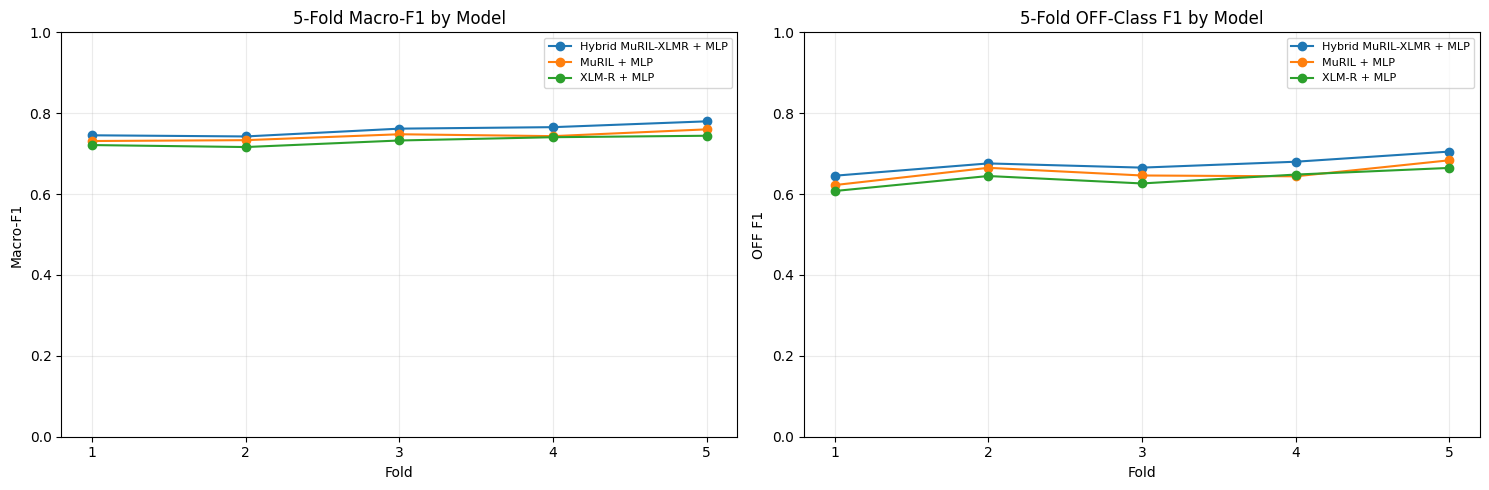

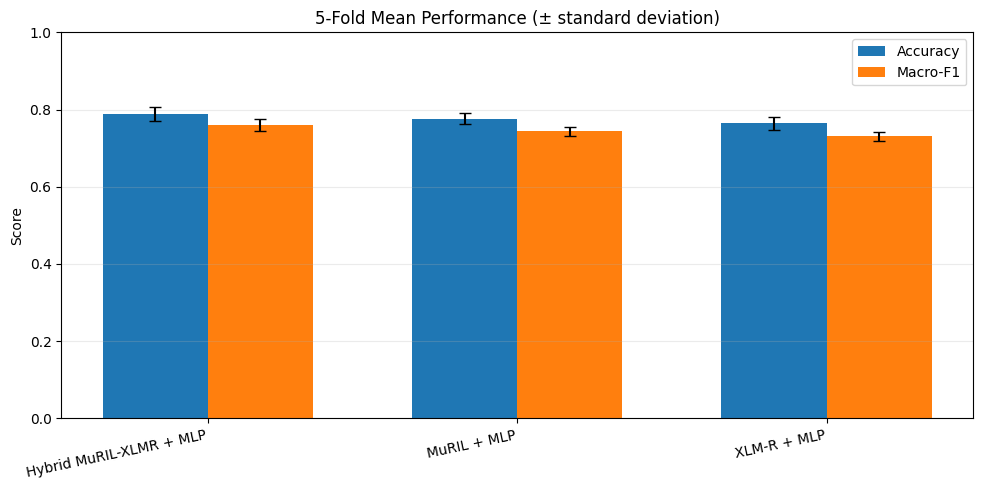

In [12]:

# ============================================================
# 13. FOLD-WISE COMPARISON GRAPHS
# ============================================================
plot_df = fold_metrics.copy()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for model_name, group in plot_df.groupby("Model"):
    axes[0].plot(group["Fold"], group["Macro-F1"], marker="o", label=model_name)
    axes[1].plot(group["Fold"], group["OFF-F1"], marker="o", label=model_name)

axes[0].set_title("5-Fold Macro-F1 by Model")
axes[0].set_xlabel("Fold")
axes[0].set_ylabel("Macro-F1")
axes[0].set_xticks(range(1, N_SPLITS + 1))
axes[0].set_ylim(0, 1)
axes[0].grid(alpha=0.25)
axes[0].legend(fontsize=8)

axes[1].set_title("5-Fold OFF-Class F1 by Model")
axes[1].set_xlabel("Fold")
axes[1].set_ylabel("OFF F1")
axes[1].set_xticks(range(1, N_SPLITS + 1))
axes[1].set_ylim(0, 1)
axes[1].grid(alpha=0.25)
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

# Mean ± standard deviation bar chart.
mean_std = fold_metrics.groupby("Model").agg(
    macro_mean=("Macro-F1", "mean"),
    macro_std=("Macro-F1", "std"),
    accuracy_mean=("Accuracy", "mean"),
    accuracy_std=("Accuracy", "std"),
)
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(mean_std))
width = 0.34
ax.bar(x - width/2, mean_std["accuracy_mean"], width, yerr=mean_std["accuracy_std"], capsize=4, label="Accuracy")
ax.bar(x + width/2, mean_std["macro_mean"], width, yerr=mean_std["macro_std"], capsize=4, label="Macro-F1")
ax.set_xticks(x)
ax.set_xticklabels(mean_std.index, rotation=12, ha="right")
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("5-Fold Mean Performance (± standard deviation)")
ax.grid(axis="y", alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()


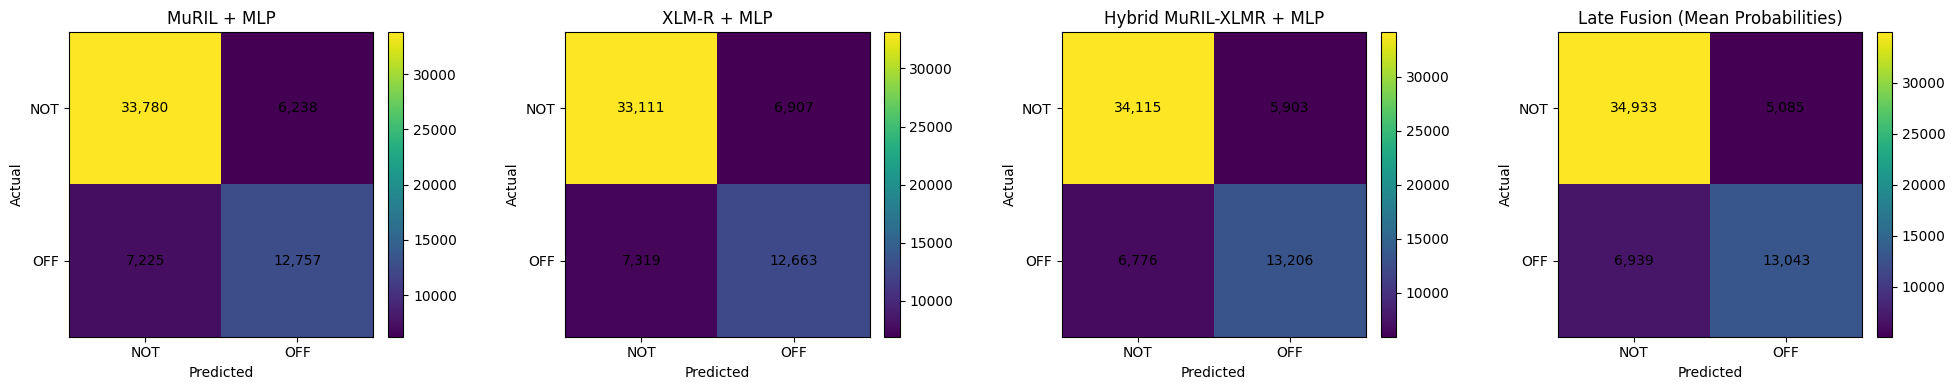


 ====================== MuRIL + MLP ======================
              precision    recall  f1-score   support

         NOT     0.8238    0.8441    0.8338     40018
         OFF     0.6716    0.6384    0.6546     19982

    accuracy                         0.7756     60000
   macro avg     0.7477    0.7413    0.7442     60000
weighted avg     0.7731    0.7756    0.7741     60000


 ====================== XLM-R + MLP ======================
              precision    recall  f1-score   support

         NOT     0.8190    0.8274    0.8232     40018
         OFF     0.6471    0.6337    0.6403     19982

    accuracy                         0.7629     60000
   macro avg     0.7330    0.7306    0.7317     60000
weighted avg     0.7617    0.7629    0.7623     60000


 ====================== Hybrid MuRIL-XLMR + MLP ======================
              precision    recall  f1-score   support

         NOT     0.8343    0.8525    0.8433     40018
         OFF     0.6911    0.6609    0.6757  

In [13]:

# ============================================================
# 14. OOF CONFUSION MATRICES + CLASSIFICATION REPORTS
# ============================================================
model_names_for_reports = list(oof_probabilities.keys())
n_models = len(model_names_for_reports)

fig, axes = plt.subplots(1, n_models, figsize=(5*n_models, 4))
if n_models == 1:
    axes = [axes]

for ax, name in zip(axes, model_names_for_reports):
    pred = oof_probabilities[name].argmax(axis=1)
    cm = confusion_matrix(y, pred, labels=[0, 1])
    im = ax.imshow(cm, interpolation="nearest")
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_xticks([0, 1], ["NOT", "OFF"])
    ax.set_yticks([0, 1], ["NOT", "OFF"])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i,j]:,}", ha="center", va="center")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

for name, probs in oof_probabilities.items():
    print("\n", "="*22, name, "="*22)
    print(classification_report(
        y,
        probs.argmax(axis=1),
        labels=[0, 1],
        target_names=["NOT", "OFF"],
        digits=4,
        zero_division=0
    ))


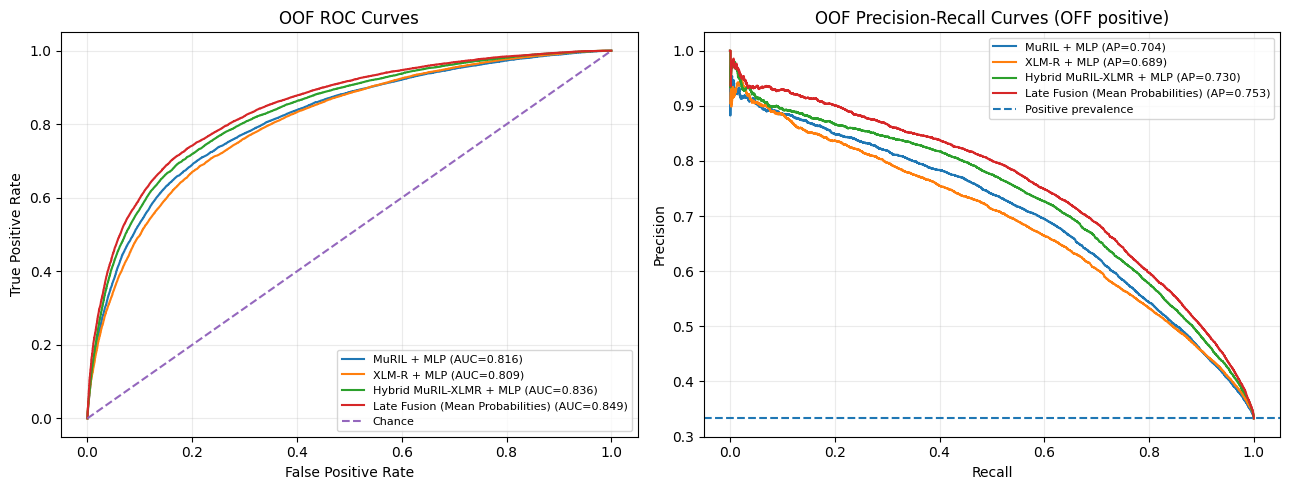

In [14]:

# ============================================================
# 15. ROC + PRECISION-RECALL CURVES
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, probs in oof_probabilities.items():
    fpr, tpr, _ = roc_curve(y, probs[:, 1])
    prec, rec, _ = precision_recall_curve(y, probs[:, 1])
    auc_value = roc_auc_score(y, probs[:, 1])
    ap_value = average_precision_score(y, probs[:, 1])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={auc_value:.3f})")
    axes[1].plot(rec, prec, label=f"{name} (AP={ap_value:.3f})")

axes[0].plot([0, 1], [0, 1], linestyle="--", label="Chance")
axes[0].set_title("OOF ROC Curves")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.25)

axes[1].axhline(y=np.mean(y), linestyle="--", label="Positive prevalence")
axes[1].set_title("OOF Precision-Recall Curves (OFF positive)")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()


In [15]:

# ============================================================
# 16. HYBRID ERROR ANALYSIS
# ============================================================
hybrid_name = "Hybrid MuRIL-XLMR + MLP"
hybrid_probs = oof_probabilities[hybrid_name]
hybrid_pred = hybrid_probs.argmax(axis=1)

error_df = train.copy()
error_df["true_label"] = [id2label[int(v)] for v in y]
error_df["predicted_label"] = [id2label[int(v)] for v in hybrid_pred]
error_df["prob_OFF"] = hybrid_probs[:, 1]
error_df["confidence"] = hybrid_probs.max(axis=1)
error_df["is_error"] = hybrid_pred != y

print("Hybrid OOF errors:", int(error_df["is_error"].sum()))
print("Hybrid OOF error rate:", round(error_df["is_error"].mean(), 4))

print("\nMost confident false positives (NOT predicted as OFF):")
display(
    error_df[
        (error_df["true_label"] == "NOT") &
        (error_df["predicted_label"] == "OFF")
    ].sort_values("prob_OFF", ascending=False)
    [["text", "true_label", "predicted_label", "prob_OFF"]]
    .head(15)
)

print("\nMost confident false negatives (OFF predicted as NOT):")
display(
    error_df[
        (error_df["true_label"] == "OFF") &
        (error_df["predicted_label"] == "NOT")
    ].sort_values("prob_OFF", ascending=True)
    [["text", "true_label", "predicted_label", "prob_OFF"]]
    .head(15)
)


Hybrid OOF errors: 12679
Hybrid OOF error rate: 0.2113

Most confident false positives (NOT predicted as OFF):


,text,true_label,predicted_label,prob_OFF
44909,@USER Link me এবং তারপর knuckles या तुम जा रहे...,NOT,OFF,0.999307
32886,@USER @USER कोई তাকে লক করা উচিত up she is not...,NOT,OFF,0.998511
22113,@USER टीबीएच এটা catchy হিসাবে fuck থো,NOT,OFF,0.997762
50037,@USER উদারপন্থীরা सुनना sucking শব্দ का the S...,NOT,OFF,0.997222
50739,@USER एरिक pay your কর এবং সোজা যাও जेल को।,NOT,OFF,0.996552
32492,@USER @USER Tucker কার্লসন নন एक बेवकूफ। वह ठी...,NOT,OFF,0.996491
47113,@USER হাঁস गधा বিষ্ঠা नहीं मज़ेदार,NOT,OFF,0.996174
40522,@ইউজার ক্যারি is truly मानसिक तौर से बीमार। वह...,NOT,OFF,0.996145
18943,@USER Holy বিষ্ঠা,NOT,OFF,0.995791
50270,@USER আপনি যদি আমাকে দিতে না পারেন टांके जब मै...,NOT,OFF,0.995584



Most confident false negatives (OFF predicted as NOT):


,text,true_label,predicted_label,prob_OFF
30840,@USER If you की तलाश में কঠিন আপনি মাথা केवल क...,OFF,NOT,0.000235
1194,@USER मैं দেখা you support বন্দুক control 😀,OFF,NOT,0.000726
54611,@USER Happy 1st birthday to Savage(Songs from ...,OFF,NOT,0.000757
15601,@USER यदि आप are looking for কঠিন আপনি মাথা के...,OFF,NOT,0.000956
12881,@USER @USER @USER नहीं চিন্তিত Antifa. তুমি পা...,OFF,NOT,0.001169
53650,@USER @USER @ইউজার পুলিশ rarely got निशाने में...,OFF,NOT,0.001232
3927,@USER यह है more what সে করে than who वह है,OFF,NOT,0.001283
7519,@USER ক্লাউন,OFF,NOT,0.001528
22962,@USER @USER @USER रिपब्लिकन लगातार बताते हैं u...,OFF,NOT,0.001552
22560,@USER স্যাভেজকে প্রথম জন্মদিনের শুভেচ্ছা (একটি...,OFF,NOT,0.001630


In [16]:

# ============================================================
# 17. SAVE OOF PREDICTIONS + EXPERIMENT MANIFEST
# ============================================================
oof_export = train[["text", "label"]].copy()
if "id" in train.columns:
    oof_export["id"] = train["id"].values
if "user" in train.columns:
    oof_export["user_group"] = train["user"].fillna("MISSING").astype(str).values

oof_export["fold"] = -1
for fold_no, (_, val_idx) in enumerate(folds, start=1):
    oof_export.loc[val_idx, "fold"] = fold_no

for name, probs in oof_probabilities.items():
    safe_name = re.sub(r"[^a-zA-Z0-9]+", "_", name.lower()).strip("_")
    oof_export[f"{safe_name}_prob_NOT"] = probs[:, 0]
    oof_export[f"{safe_name}_prob_OFF"] = probs[:, 1]
    oof_export[f"{safe_name}_prediction"] = [
        id2label[int(v)] for v in probs.argmax(axis=1)
    ]

oof_path = WORK_DIR / "hybrid_5fold_oof_predictions.csv"
oof_export.to_csv(oof_path, index=False)

manifest = {
    "experiment": "MuRIL + XLM-R frozen embedding fusion with user-grouped 5-fold CV",
    "muril_checkpoint": MURIL_CHECKPOINT,
    "xlmr_checkpoint": XLMR_CHECKPOINT,
    "max_length": MAX_LENGTH,
    "n_splits": N_SPLITS,
    "mlp_epochs_max": MLP_EPOCHS,
    "mlp_patience": MLP_PATIENCE,
    "mlp_batch_size": MLP_BATCH_SIZE,
    "focal_gamma": FOCAL_GAMMA,
    "seed": RANDOM_STATE,
    "training_rows": len(train),
    "distinct_cv_groups": int(pd.Series(cv_groups).nunique()),
    "known_users": int(train["user"].nunique(dropna=True)) if "user" in train.columns else None,
    "residual_cross_group_duplicate_texts": cross_group_duplicate_texts,
    "encoder_finetuning": False,
    "hybrid_fusion": "concatenate mean-pooled frozen MuRIL and XLM-R embeddings, then train MLP",
}
with open(WORK_DIR / "hybrid_5fold_experiment_manifest.json", "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2)

print("Saved artifacts:")
for p in [
    WORK_DIR / "hybrid_5fold_fold_metrics.csv",
    WORK_DIR / "hybrid_5fold_oof_summary.csv",
    WORK_DIR / "hybrid_5fold_training_history.csv",
    oof_path,
    WORK_DIR / "hybrid_5fold_experiment_manifest.json",
]:
    print(" -", p)
print("Fold models and scalers:", MODEL_DIR)
print("Cached embeddings:", CACHE_DIR)


Saved artifacts:
 - /kaggle/working/hybrid_5fold_fold_metrics.csv
 - /kaggle/working/hybrid_5fold_oof_summary.csv
 - /kaggle/working/hybrid_5fold_training_history.csv
 - /kaggle/working/hybrid_5fold_oof_predictions.csv
 - /kaggle/working/hybrid_5fold_experiment_manifest.json
Fold models and scalers: /kaggle/working/hybrid_cv_fold_models
Cached embeddings: /kaggle/working/hybrid_cv_embedding_cache



# 18. How to report this experiment

Report all four rows from `hybrid_5fold_oof_summary.csv`, especially:

- Pooled OOF Accuracy and Macro-F1
- Fold mean ± standard deviation for the three trained classifiers
- `OFF` Precision, Recall, and F1
- ROC-AUC and PR-AUC
- Fold sizes and fold-wise class ratios

## Limitations to disclose

1. **Frozen encoders:** this experiment trains the MLP fusion head, not the transformer encoders. Do not describe it as joint fine-tuning.
2. **User-group CV:** known user identities are held out by fold. Missing user values use the ID/text fallback. The number and size of user groups are uneven, so fold-level scores and standard deviation matter.
3. **Residual duplicate text:** exact normalized text can still occur across distinct known-user groups. The notebook counts and reports these cases. Do not claim that every source/text duplicate is fully isolated.
4. **Official dev/test:** neither is used in the 5-fold experiment. Their shared IDs/text with train should be handled in a separate decontaminated external-evaluation experiment.
5. **No score is assumed:** results must be generated by running the notebook on Kaggle GPU.

## Recommended next experiment

If the hybrid frozen-embedding MLP improves over both individual encoders consistently across folds, the next research step is **end-to-end fine-tuning**: fine-tune XLM-R on the same fold protocol, then try a compact gated/attention fusion head. If the hybrid does not improve, inspect false positives/negatives and test a weighted or gated fusion before increasing model size.
